# A harder repair case and a clearer probe relay

This notebook documents the preparation of a **second** repair case for Read Between the Weights. It uses a different trained checkpoint and fresh data splits. All numbers here are operator-side **development validation**, not LLM responses or held-out results. This notebook records preparation; the subsequent reviewer results are in notebook 11.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
ROOT=Path.cwd().resolve()
if not (ROOT/'experiment.json').exists(): ROOT=ROOT.parent
setup=json.loads((ROOT/'results/repair_v2_setup.json').read_text())
OUT=ROOT/'results/figures'; OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':300,'axes.spines.top':False,'axes.spines.right':False})
def save(fig,name):
    fig.savefig(OUT/f'{name}.png',bbox_inches='tight',facecolor='white')
    fig.savefig(OUT/f'{name}.svg',bbox_inches='tight',facecolor='white')
print('Development sample:', setup['validation_count'])
print('Status:', setup['phase'])

Development sample: 2048
Status: prepared_not_run


## Why a second case?

In the first experiment, Astra proposed the same successful edit in every condition, including weights-only. The new checkpoint has two deliberately introduced changes, so a single permitted edit need not undo all of the degradation. A different trained model and independent data make this a new case, but do not establish that it will be harder for either reviewer until they are tested.

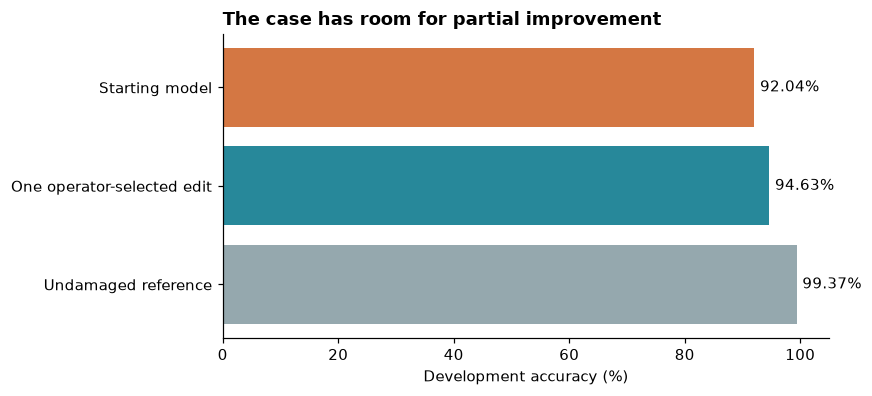

The middle bar is an operator demonstration, not an LLM result.


In [2]:
values=[setup['starting_accuracy']*100,setup['demonstrated_single_edit_accuracy']*100,setup['reference_accuracy']*100]
fig,ax=plt.subplots(figsize=(8,3.7)); bars=ax.barh(['Starting model','One operator-selected edit','Undamaged reference'],values,color=['#d47743','#27889a','#95a8ae'])
ax.set_xlim(0,105); ax.invert_yaxis(); ax.set_xlabel('Development accuracy (%)');ax.set_title('The case has room for partial improvement',loc='left',fontweight='bold')
for bar,v in zip(bars,values):ax.text(v+1,bar.get_y()+bar.get_height()/2,f'{v:.2f}%',va='center')
fig.tight_layout();save(fig,'30_repair_v2_development');plt.show()
print('The middle bar is an operator demonstration, not an LLM result.')

## Where is the weakness?

The chart compares the starting model with one permissible edit on the same development sample. Quadrants group examples by the signs of the first two inputs. The reference edit was chosen using development data, so its result is an illustration of available opportunity rather than an unbiased performance estimate.

The demonstrated edit improves Q-- but slightly reduces Q-+ accuracy. That trade-off gives reviewers a reason to check for regressions as well as overall gains.

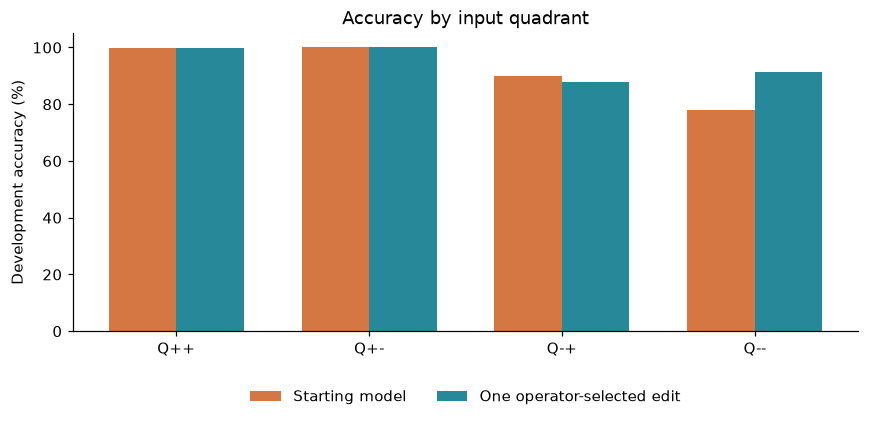

In [3]:
q=['Q++','Q+-','Q-+','Q--']; x=np.arange(4); width=.35
start=[setup['starting_quadrants'][k]['accuracy']*100 for k in q]
after=[setup['demonstrated_single_edit_quadrants'][k]['accuracy']*100 for k in q]
fig,ax=plt.subplots(figsize=(8,4));ax.bar(x-width/2,start,width,label='Starting model',color='#d47743');ax.bar(x+width/2,after,width,label='One operator-selected edit',color='#27889a')
ax.set(xticks=x,xticklabels=q,ylim=(0,105),ylabel='Development accuracy (%)',title='Accuracy by input quadrant');ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2);fig.tight_layout();save(fig,'31_repair_v2_quadrants');plt.show()

## Clearer instructions for probe sessions

- **Weights only:** return a final edit immediately; do not request probes.
- **Fixed probes:** reply `READY`; after each of the first three fixed batches, reply `READY` again. After the fourth, return the edit.
- **Adaptive probes:** return one JSON batch of eight inputs, wait for logits, and repeat. After the fourth batch, return the edit.

The relay repeats the appropriate next action and batch number after each response. Both reviewers receive the same condition-specific instructions and the same probe budget. In a later Qwen pilot on the handcrafted calibration model, all three revised protocols were completed. See notebook 10 for calibration and notebook 11 for the subsequent harder-checkpoint results.

## Before interpreting future results

Six separate reviewer/condition sessions are prepared. Their new final evaluation split was scored only after the cohort was frozen; see notebook 11. The earlier experiment remains unchanged. The new study shares the existing local budget ledger; provider-reported output overruns and billing uncertainty still need to be recorded. Any incomplete session must remain missing, not a zero score.